In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv(
    "../Data/Processed/cleaned_customers.csv"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (2000, 17)


,order_id,customer_id,age,product_id,country,signup_date,last_purchase_date,cancellations_count,subscription_status,order_date,unit_price,quantity,purchase_frequency,preferred_category,product_name,category,gender
0,ORD5000,CUST1000,39,PROD200,Canada,1/7/2021,2/21/2023,0,active,8/20/2024,78.21,5,37,Sports,Football,Sports,Female
1,ORD5001,CUST1001,61,PROD201,USA,10/19/2020,12/8/2021,0,active,7/17/2025,64.02,8,35,Sports,Refrigerator,Home,Female
2,ORD5002,CUST1002,26,PROD202,Pakistan,6/10/2023,9/4/2023,3,cancelled,3/12/2025,604.14,2,44,Electronics,Hoodie,Clothing,Female
3,ORD5003,CUST1003,54,PROD203,India,7/30/2023,2/20/2024,4,paused,9/19/2024,84.66,4,1,Sports,Conditioner,Beauty,Male
4,ORD5004,CUST1004,50,PROD204,India,12/9/2020,9/14/2024,0,active,8/8/2024,62.66,7,35,Sports,Smartwatch,Electronics,Male


In [3]:
df.describe()

,age,cancellations_count,unit_price,quantity,purchase_frequency
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,44.080500,2.441500,324.719460,4.948500,25.158000
std,14.798091,1.702359,361.548405,2.557757,14.158752
min,18.000000,0.000000,2.850000,1.000000,1.000000
25%,31.000000,1.000000,111.127500,3.000000,13.000000
50%,45.000000,2.000000,206.515000,5.000000,25.000000
75%,57.000000,4.000000,384.507500,7.000000,37.000000
max,69.000000,5.000000,1991.630000,9.000000,49.000000


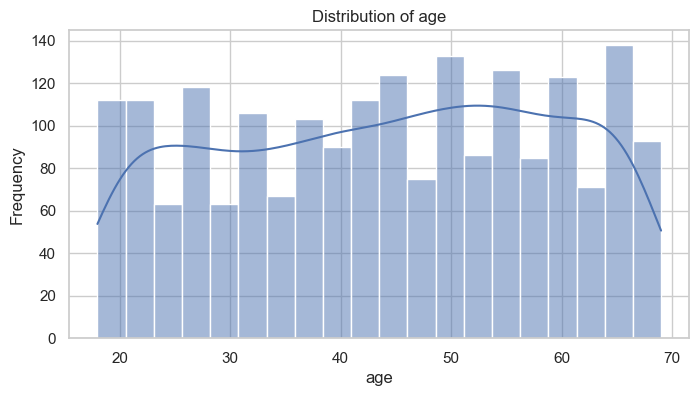

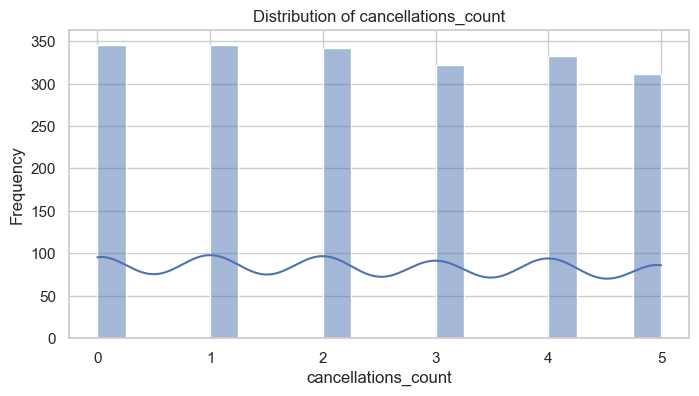

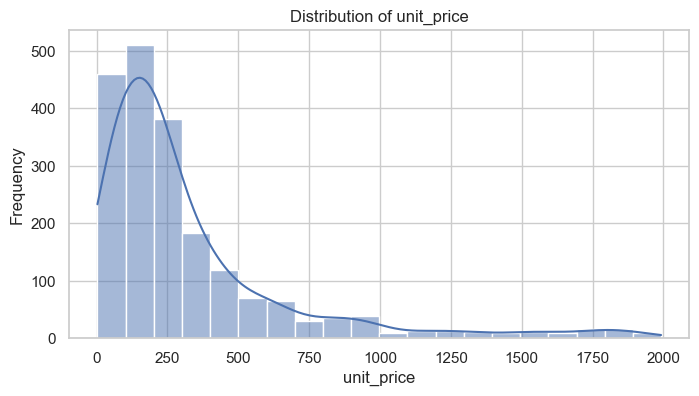

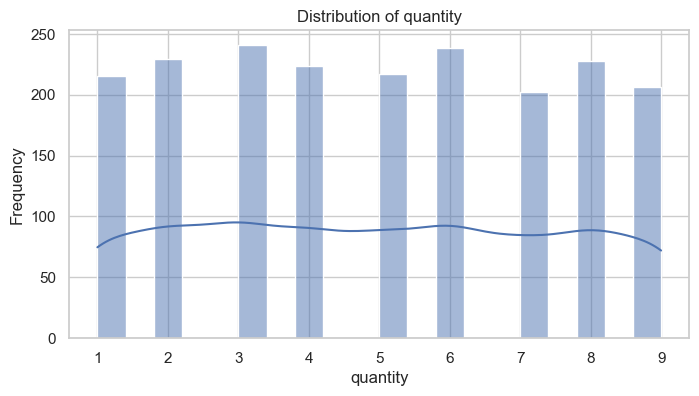

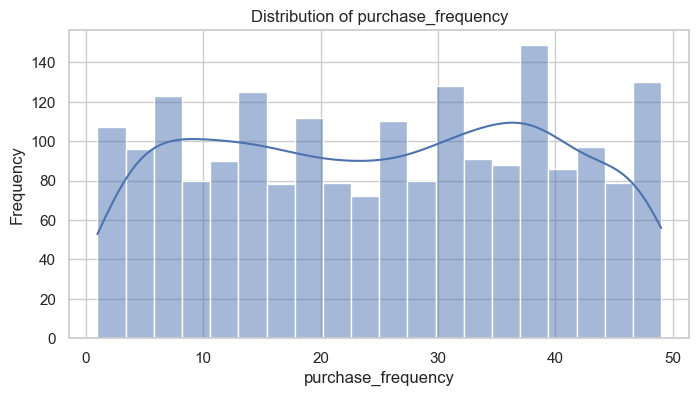

In [4]:
numerical_columns = df.select_dtypes(
    include=np.number
).columns

for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=20
    )

    plt.title(f"Distribution of {column}")
    plt.xlabel(column)
    plt.ylabel("Frequency")

    plt.show()

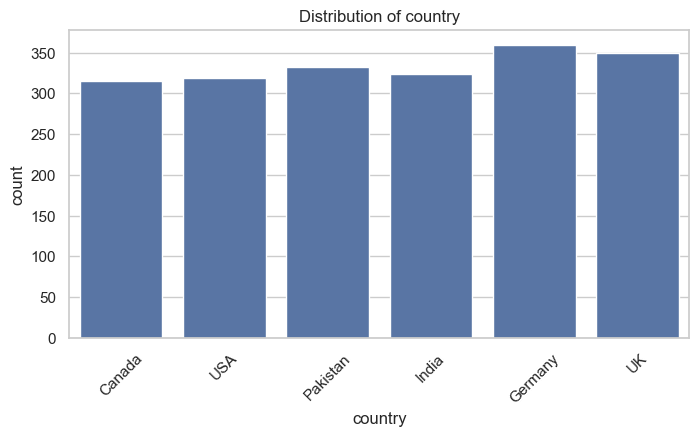

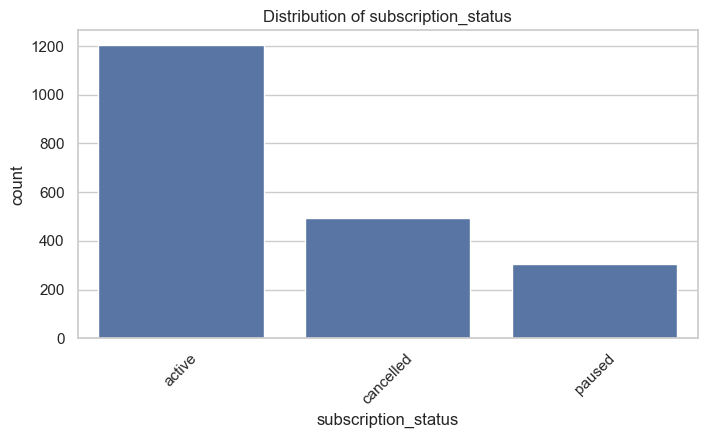

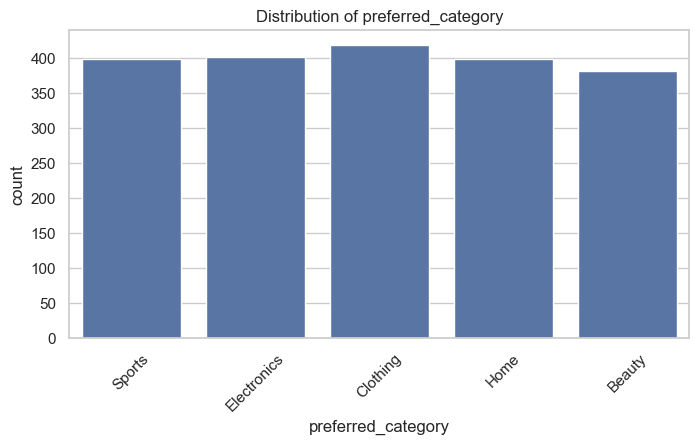

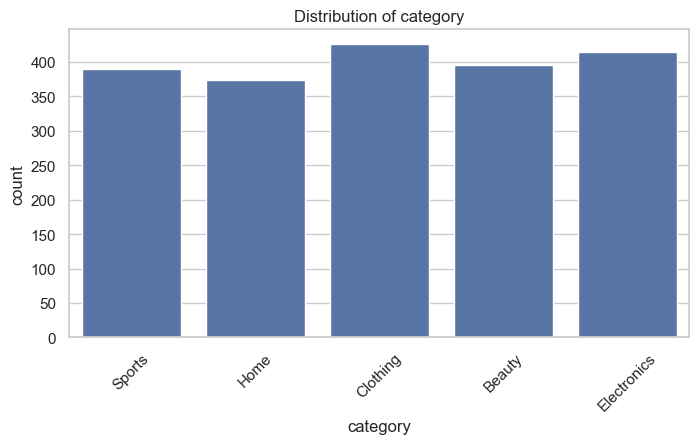

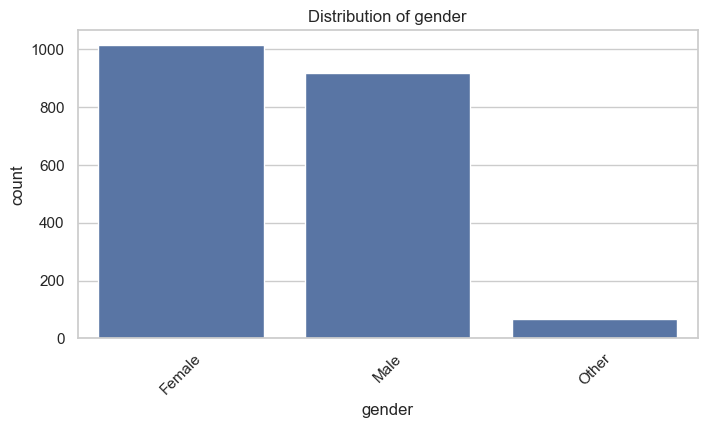

In [6]:
categorical_columns = df.select_dtypes(
    include=["object", "str","category"]
).columns

for column in categorical_columns:

    if df[column].nunique() <= 20:

        plt.figure(figsize=(8, 4))

        sns.countplot(
            data=df,
            x=column
        )

        plt.title(f"Distribution of {column}")
        plt.xticks(rotation=45)

        plt.show()

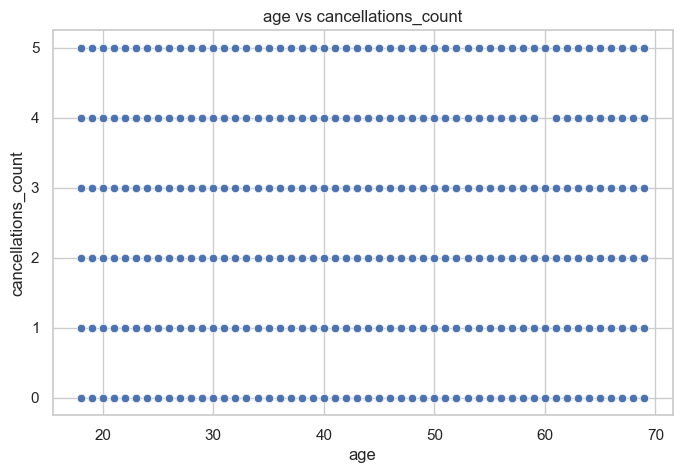

In [7]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns.tolist()

if len(numeric_cols) >= 2:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x=numeric_cols[0],
        y=numeric_cols[1]
    )

    plt.title(
        f"{numeric_cols[0]} vs {numeric_cols[1]}"
    )

    plt.show()

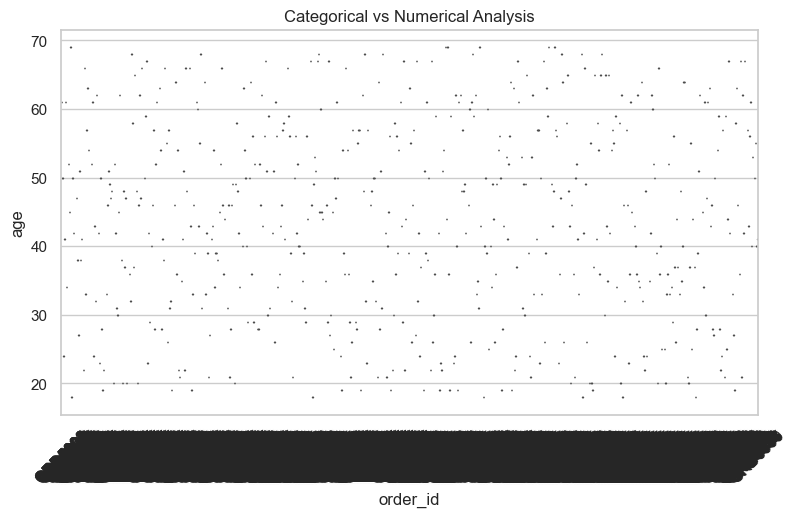

In [8]:
if len(categorical_columns) > 0 and len(numeric_cols) > 0:

    plt.figure(figsize=(9, 5))

    sns.boxplot(
        data=df,
        x=categorical_columns[0],
        y=numeric_cols[0]
    )

    plt.xticks(rotation=45)
    plt.title("Categorical vs Numerical Analysis")

    plt.show()

In [9]:
correlation = df.select_dtypes(
    include=np.number
).corr()

display(correlation)

,age,cancellations_count,unit_price,quantity,purchase_frequency
age,1.000000,0.006988,-0.030912,0.041570,0.009055
cancellations_count,0.006988,1.000000,0.004567,0.004650,-0.014788
unit_price,-0.030912,0.004567,1.000000,-0.628622,-0.005085
quantity,0.041570,0.004650,-0.628622,1.000000,0.012767
purchase_frequency,0.009055,-0.014788,-0.005085,0.012767,1.000000


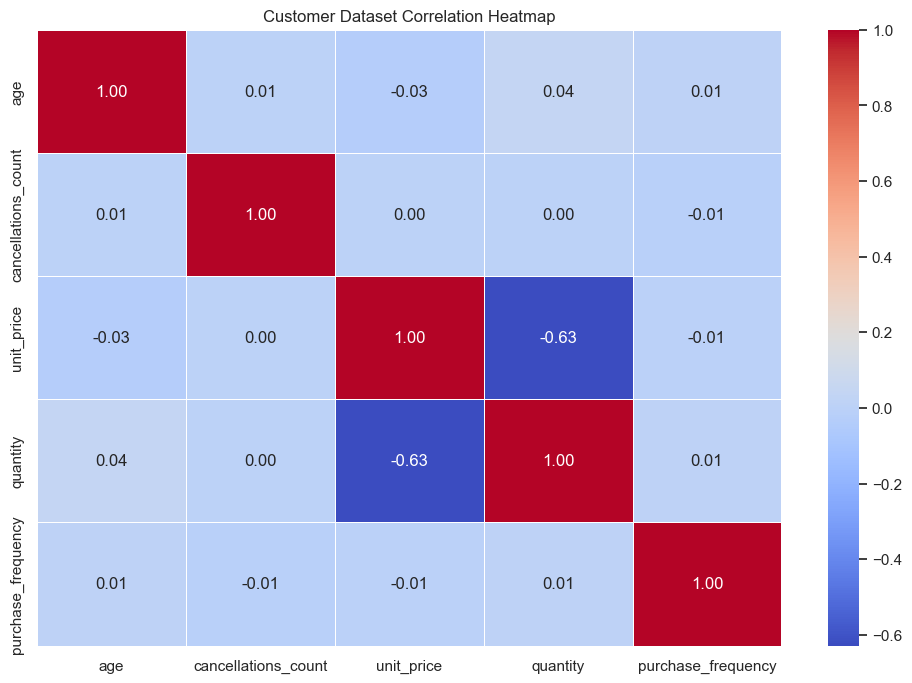

In [10]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Customer Dataset Correlation Heatmap")

plt.show()

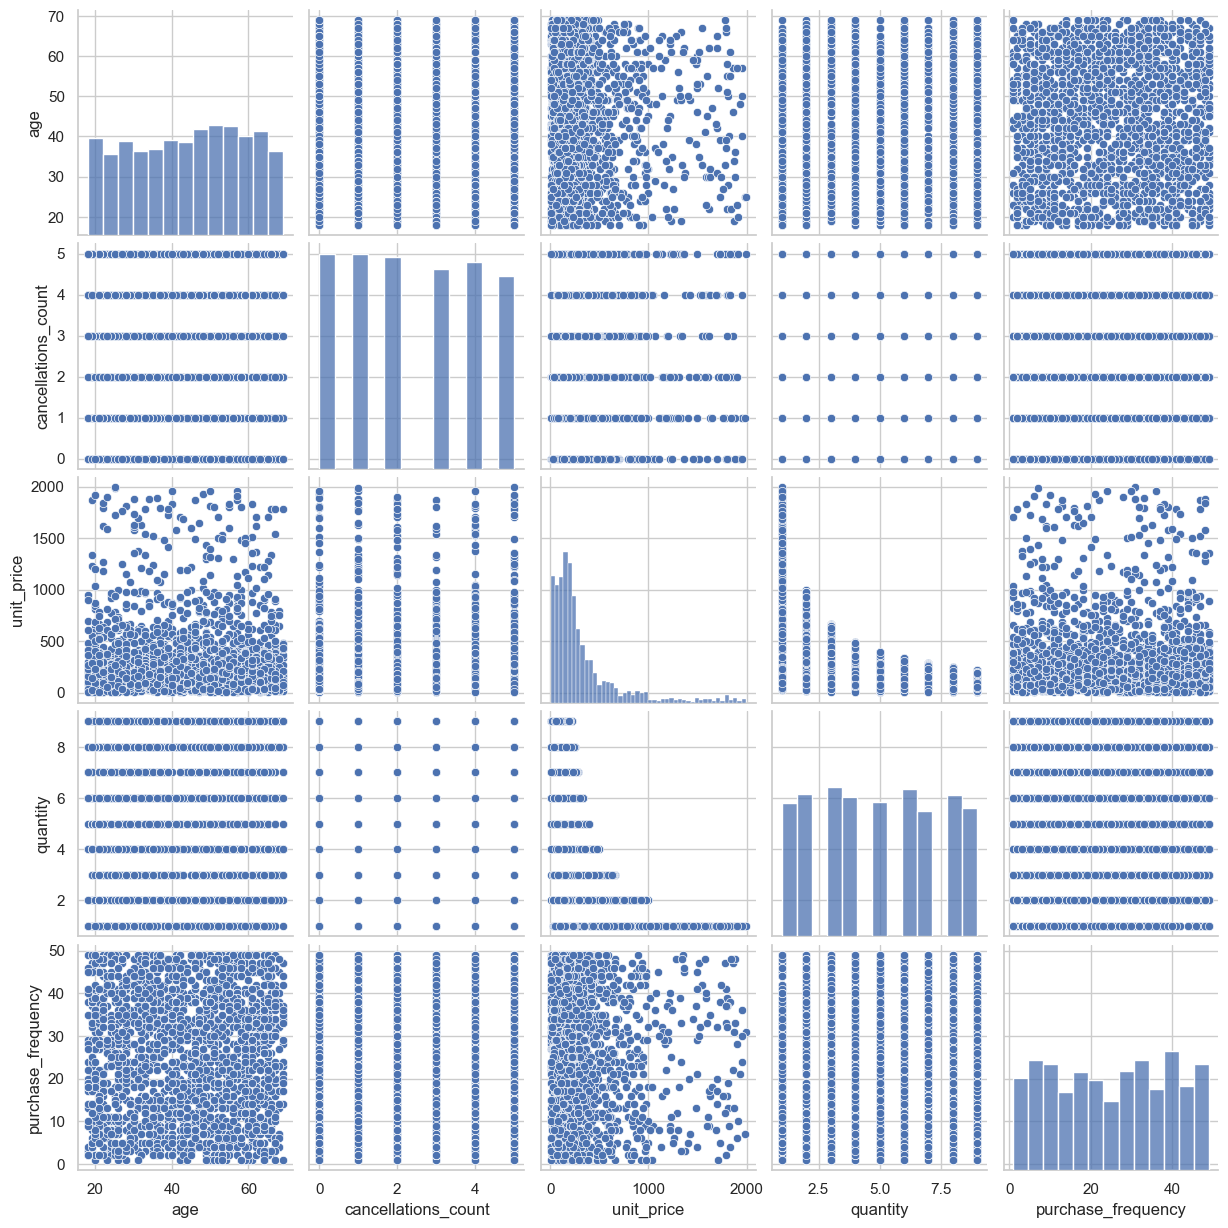

In [11]:
pair_columns = numeric_cols[:5]

if len(pair_columns) >= 2:

    sns.pairplot(
        df[pair_columns].dropna()
    )

    plt.show()

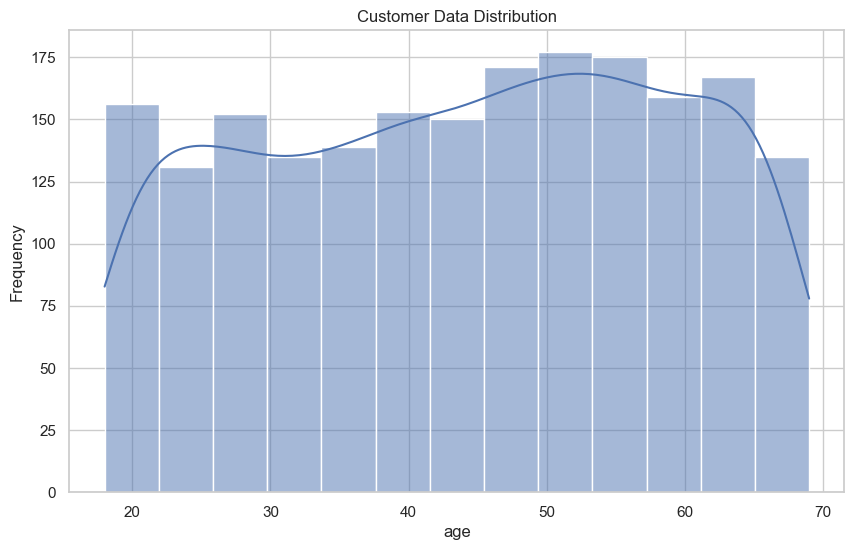

In [15]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create Visualization folder if it does not exist
os.makedirs("../Visualization", exist_ok=True)

# Create histogram
plt.figure(figsize=(10, 6))

sns.histplot(df[numeric_cols[0]], kde=True)

plt.title("Customer Data Distribution")
plt.xlabel(numeric_cols[0])
plt.ylabel("Frequency")

# Save visualization
plt.savefig(
    "../Visualization/customer_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()